In [1]:
!apt-get update -qq
!apt-get install -y g++ libopencv-dev libcurl4-openssl-dev

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
g++ is already the newest version (4:13.2.0-7ubuntu1).
libopencv-dev is already the newest version (4.6.0+dfsg-13.1ubuntu1).
libcurl4-openssl-dev is already the newest version (8.5.0-2ubuntu10.16).
0 upgraded, 0 newly installed, 0 to remove and 98 not upgraded.


In [2]:
%%writefile detect_faces.cpp
#include <iostream>
#include <vector>
#include <string>
#include <opencv2/opencv.hpp>
#include <opencv2/objdetect.hpp>
#include <curl/curl.h>

// Callback для загрузки изображения по URL
size_t WriteMemoryCallback(void* contents, size_t size, size_t nmemb, void* userp) {
    size_t realsize = size * nmemb;
    auto* mem = static_cast<std::vector<uchar>*>(userp);
    auto* ptr = static_cast<uchar*>(contents);
    mem->insert(mem->end(), ptr, ptr + realsize);
    return realsize;
}

std::vector<uchar> download(const std::string& url) {
    std::vector<uchar> data;
    CURL* curl = curl_easy_init();
    if (curl) {
        curl_easy_setopt(curl, CURLOPT_URL, url.c_str());
        curl_easy_setopt(curl, CURLOPT_WRITEFUNCTION, WriteMemoryCallback);
        curl_easy_setopt(curl, CURLOPT_WRITEDATA, &data);
        curl_easy_setopt(curl, CURLOPT_FOLLOWLOCATION, 1L);
        curl_easy_setopt(curl, CURLOPT_USERAGENT, "libcurl-agent/1.0");
        curl_easy_perform(curl);
        curl_easy_cleanup(curl);
    }
    return data;
}

// Универсальная загрузка
cv::Mat loadImage(const std::string& source) {
    if (source.rfind("http", 0) == 0) {
        auto bytes = download(source);
        return cv::imdecode(bytes, cv::IMREAD_COLOR);
    }
    return cv::imread(source);
}

int main(int argc, char** argv) {
    std::string source = (argc > 1) ? argv[1]
        : "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg";

    std::cout << "=== Загрузка: " << source << " ===" << std::endl;
    cv::Mat image = loadImage(source);
    if (image.empty()) {
        std::cerr << "Не удалось загрузить изображение!" << std::endl;
        return 1;
    }
    std::cout << "Размер: " << image.cols << "x" << image.rows << std::endl;

    // Загрузка каскадов
    cv::CascadeClassifier face_cascade, eye_cascade;
    if (!face_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_frontalface_default.xml") ||
        !eye_cascade.load("/usr/share/opencv4/haarcascades/haarcascade_eye.xml")) {
        std::cerr << "Не удалось загрузить каскады" << std::endl;
        return 1;
    }

    // Предобработка
    cv::Mat gray;
    cv::cvtColor(image, gray, cv::COLOR_BGR2GRAY);
    cv::equalizeHist(gray, gray);

    // Детекция лиц
    std::vector<cv::Rect> faces;
    face_cascade.detectMultiScale(gray, faces, 1.1, 5, 0, cv::Size(30, 30));
    std::cout << "Распознано лиц: " << faces.size() << std::endl;

    // Детекция глаз (в верхней 60% области каждого лица)
    int total_eyes = 0;
    int idx = 0;
    for (const auto& face : faces) {
        ++idx;
        // Рамка лица + подпись
        cv::rectangle(image, face, cv::Scalar(0, 255, 0), 2);
        std::string label = "Face " + std::to_string(idx);
        int baseline = 0;
        cv::Size text_size = cv::getTextSize(label, cv::FONT_HERSHEY_SIMPLEX, 0.6, 2, &baseline);
        cv::Point text_org(face.x, face.y - 5);
        if (text_org.y < text_size.height) text_org.y = face.y + text_size.height + 5;
        cv::rectangle(image,
            cv::Point(text_org.x, text_org.y - text_size.height - 2),
            cv::Point(text_org.x + text_size.width, text_org.y + 2),
            cv::Scalar(0, 255, 0), cv::FILLED);
        cv::putText(image, label, text_org, cv::FONT_HERSHEY_SIMPLEX, 0.6,
            cv::Scalar(0, 0, 0), 2);

        // Глаза ищутся только в верхней части лица
        cv::Mat face_roi_gray = gray(face);
        cv::Mat face_roi_gray_top = face_roi_gray(
            cv::Rect(0, 0, face.width, face.height * 6 / 10));

        std::vector<cv::Rect> eyes;
        eye_cascade.detectMultiScale(face_roi_gray_top, eyes, 1.1, 10);
        std::cout << "  Face #" << idx << ": распознано глаз = " << eyes.size() << std::endl;
        total_eyes += eyes.size();

        for (const auto& eye : eyes) {
            cv::Rect eye_abs(face.x + eye.x, face.y + eye.y, eye.width, eye.height);
            cv::rectangle(image, eye_abs, cv::Scalar(255, 0, 0), 2);
        }
    }
    std::cout << "итого распознано глаз: " << total_eyes << std::endl;

    cv::imwrite("faces_detected.jpg", image);
    std::cout << "Результат сохранён: faces_detected.jpg" << std::endl;
    return 0;
}

Overwriting detect_faces.cpp


In [3]:
!g++ detect_faces.cpp -o detect_faces $(pkg-config --cflags --libs opencv4 libcurl) -std=c++17

In [4]:
import matplotlib.pyplot as plt
import cv2

def show_result(title):
    img = cv2.imread('faces_detected.jpg')
    if img is not None:
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.figure(figsize=(8, 8))
        plt.imshow(img_rgb)
        plt.title(title)
        plt.axis('off')
        plt.show()

=== Загрузка: https://img.magnific.com/premium-photo/handsome-caucasian-man-isolated-white_251136-32545.jpg?semt=ais_hybrid ===
Размер: 418x626
Распознано лиц: 1
  Face #1: распознано глаз = 2
итого распознано глаз: 2
Результат сохранён: faces_detected.jpg


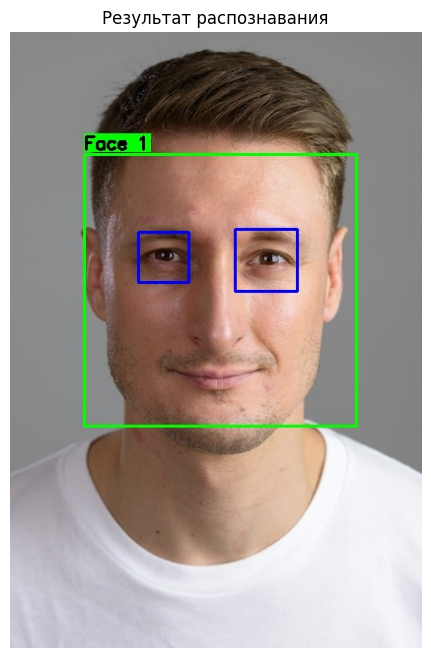

=== Загрузка: https://camo.githubusercontent.com/25c08195bcfc8601881bce6d42abfdb0b89e22dee01420ca8c8561e181f46e6c/68747470733a2f2f696d6167652e636976697461692e636f6d2f7847316e6b714b544d7a474476704c727146543757412f34636332643362382d613761342d343735382d623266632d6634353130333338376630372f6f726967696e616c3d747275652f34636332643362382d613761342d343735382d623266632d6634353130333338376630372e6a706567 ===
Размер: 832x1248
Распознано лиц: 6
  Face #1: распознано глаз = 0
  Face #2: распознано глаз = 0
  Face #3: распознано глаз = 0
  Face #4: распознано глаз = 2
  Face #5: распознано глаз = 2
  Face #6: распознано глаз = 2
итого распознано глаз: 6
Результат сохранён: faces_detected.jpg


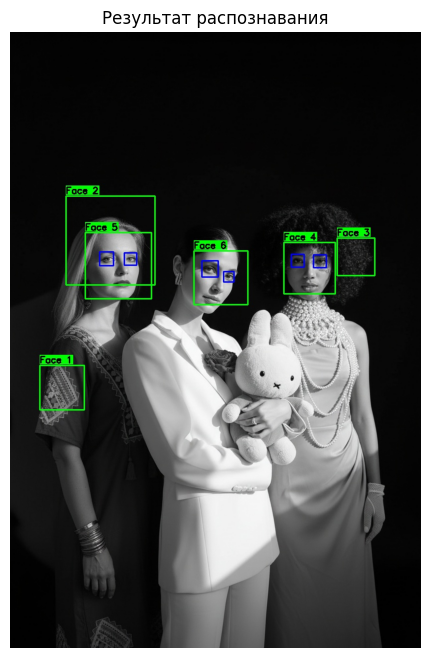

=== Загрузка: https://i.pinimg.com/originals/c5/e2/c4/c5e2c4259d89f2bd33701613756d602c.png ===
Размер: 736x1104
Распознано лиц: 1
  Face #1: распознано глаз = 0
итого распознано глаз: 0
Результат сохранён: faces_detected.jpg


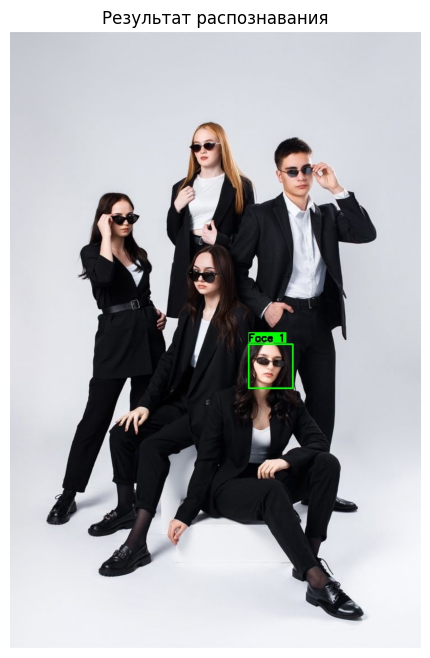

In [5]:
# Обычное
!./detect_faces "https://img.magnific.com/premium-photo/handsome-caucasian-man-isolated-white_251136-32545.jpg?semt=ais_hybrid"
show_result('Результат распознавания')
# Группа
!./detect_faces "https://camo.githubusercontent.com/25c08195bcfc8601881bce6d42abfdb0b89e22dee01420ca8c8561e181f46e6c/68747470733a2f2f696d6167652e636976697461692e636f6d2f7847316e6b714b544d7a474476704c727146543757412f34636332643362382d613761342d343735382d623266632d6634353130333338376630372f6f726967696e616c3d747275652f34636332643362382d613761342d343735382d623266632d6634353130333338376630372e6a706567"
show_result('Результат распознавания')
# Очки
!./detect_faces "https://i.pinimg.com/originals/c5/e2/c4/c5e2c4259d89f2bd33701613756d602c.png"
show_result('Результат распознавания')

# Задание 3. Сравнение реального и распознанного количества лиц и глаз

## Результаты экспериментов

| Фото | Описание | Реально лиц | Распознано лиц | Реально глаз | Распознано глаз |
|:----:|----------|:-----------:|:--------------:|:------------:|:---------------:|
| 1 | Мужчина анфас | 1 | 1 ✓ | 2 | 2 ✓ |
| 2 | Групповое фото | 3 | 6 ✗ | 6 | 6 ✓ |
| 3 | Люди в тёмных очках | 5 | 1 ✗ | 10 | 0 ✗ |

## Почему так получается

1. Каскад обучен на фронтальных лицах. Лица в профиль, повёрнутые или частично перекрытые ищутся плохо.

2. Очки —  помеха для каскада. Каскад глаз обучен на открытых глазах с видимой радужкой и белком, тёмные стёкла уничтожают эти признаки.

3. На сложных текстурах могут случайно сформироваться паттерны, похожие на лицо. Отсюда 6 лиц вместо 3 на групповом фото.